##  Setup: import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, RocCurveDisplay)

RANDOM_STATE = 123
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


##  Load the dataset




In [2]:
data = pd.read_csv("heart.csv")
print("Loaded heart.csv ->", data.shape[0], "rows x", data.shape[1], "columns")

Loaded heart.csv -> 303 rows x 14 columns


## First look at the data

In [3]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
data.sample(5, random_state=RANDOM_STATE)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
11,48,0,2,130,275,0,1,139,0,0.2,2,0,2,1
292,58,0,0,170,225,1,0,146,1,2.8,1,2,1,0
269,56,1,0,130,283,1,0,103,1,1.6,0,0,3,0
268,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0
94,45,0,1,112,160,0,1,138,0,0.0,1,0,2,1


In [5]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
data.shape

(303, 14)

## EDA

 We check four things: **duplicates**, **hidden missing values**, **wrong code labels** and **the meaning of `target`**.

In [8]:
print("Missing values (NaN):", int(data.isnull().sum().sum()))
print("Duplicate rows      :", int(data.duplicated().sum()))

Missing values (NaN): 0
Duplicate rows      : 1


In [9]:
print("ca   value counts:", data["ca"].value_counts().sort_index().to_dict())
print("thal value counts:", data["thal"].value_counts().sort_index().to_dict())

ca   value counts: {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thal value counts: {0: 2, 1: 18, 2: 166, 3: 117}



here ca = 4 (5 rows) and thal = 0 (2 rows) are impossible values
We also drop the exact duplicate row, otherwise the same patient could appear in both the training and the test set.

In [10]:
data = data.drop_duplicates().reset_index(drop=True)
data.loc[data["ca"] == 4, "ca"] = np.nan
data.loc[data["thal"] == 0, "thal"] = np.nan
print("Rows after removing duplicates:", len(data))
print("Missing values now:\n", data.isnull().sum()[lambda s: s > 0])

Rows after removing duplicates: 302
Missing values now:
 ca      4
thal    2
dtype: int64


In [11]:
print("Share with target = 1 :", round(data["target"].mean() * 100, 1), "%")
print(data.groupby("sex")["target"].mean().rename({0: "female", 1: "male"}).round(2))

Share with target = 1 : 54.3 %
sex
female    0.75
male      0.45
Name: target, dtype: float64


Females have a much higher `target = 1` rate than males, which only makes sense if `target = 1` means **no disease**. So we flip it, making **1 = heart disease** (the natural "positive" class for metrics such as false-negative rate).

Set `FLIP_TARGET = False` below if you ever want to use the original meaning. Model accuracy does not change either way, only how the results are described.

In [12]:
FLIP_TARGET = True
if FLIP_TARGET:
    data["target"] = 1 - data["target"]

print(data["target"].value_counts().rename({0: "no disease (0)", 1: "disease (1)"}))

target
no disease (0)    164
disease (1)       138
Name: count, dtype: int64


## Make the data easier to read



In [13]:
data.columns = ["age", "sex", "chest_pain_type", "resting_blood_pressure", "cholesterol",
                "fasting_blood_sugar", "rest_ecg", "max_heart_rate_achieved",
                "exercise_induced_angina", "st_depression", "st_slope",
                "num_major_vessels", "thalassemia", "target"]

label_maps = {
    "sex":                     {0: "female", 1: "male"},
    "chest_pain_type":         {0: "asymptomatic", 1: "atypical angina", 2: "non-anginal pain", 3: "typical angina"},
    "fasting_blood_sugar":     {0: "<= 120 mg/dl", 1: "> 120 mg/dl"},
    "rest_ecg":                {0: "left ventricular hypertrophy", 1: "normal", 2: "ST-T wave abnormality"},
    "exercise_induced_angina": {0: "no", 1: "yes"},
    "st_slope":                {0: "downsloping", 1: "flat", 2: "upsloping"},
    "thalassemia":             {1: "fixed defect", 2: "normal", 3: "reversible defect"},
    "target":                  {0: "no disease", 1: "disease"},
}

eda = data.copy()
for column, mapping in label_maps.items():
    eda[column] = eda[column].map(mapping)

eda.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,male,typical angina,145,233,> 120 mg/dl,left ventricular hypertrophy,150,no,2.3,downsloping,0.0,fixed defect,no disease
1,37,male,non-anginal pain,130,250,<= 120 mg/dl,normal,187,no,3.5,downsloping,0.0,normal,no disease
2,41,female,atypical angina,130,204,<= 120 mg/dl,left ventricular hypertrophy,172,no,1.4,upsloping,0.0,normal,no disease
3,56,male,atypical angina,120,236,<= 120 mg/dl,normal,178,no,0.8,upsloping,0.0,normal,no disease
4,57,female,asymptomatic,120,354,<= 120 mg/dl,normal,163,yes,0.6,upsloping,0.0,normal,no disease


## Exploratory Data Analysis (EDA)

### 7.1 How many patients have heart disease?

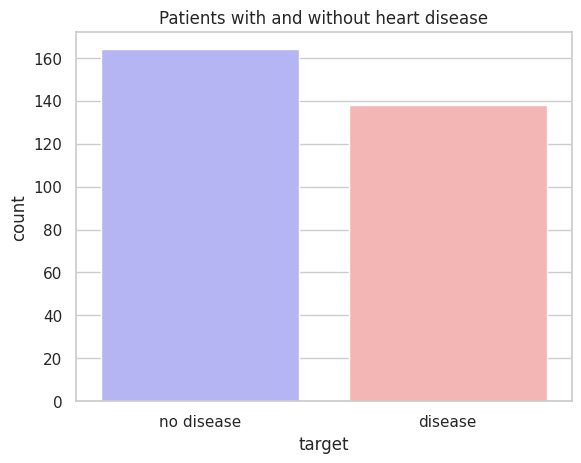

target
no disease    164
disease       138
Name: count, dtype: int64


In [14]:
ax = sns.countplot(x="target", data=eda, order=["no disease", "disease"], hue="target",
                   palette="bwr", legend=False)
ax.set_title("Patients with and without heart disease")
plt.show()

print(eda["target"].value_counts())

In [15]:
pct_female = (data["sex"] == 0).mean() * 100
pct_male   = (data["sex"] == 1).mean() * 100
print(f"Percentage of female patients: {pct_female:.2f}%")
print(f"Percentage of male patients  : {pct_male:.2f}%")

pct_no  = (data["target"] == 0).mean() * 100
pct_yes = (data["target"] == 1).mean() * 100
print(f"Percentage without heart disease: {pct_no:.2f}%")
print(f"Percentage with heart disease   : {pct_yes:.2f}%")

Percentage of female patients: 31.79%
Percentage of male patients  : 68.21%
Percentage without heart disease: 54.30%
Percentage with heart disease   : 45.70%


### Heart disease rate for males and females

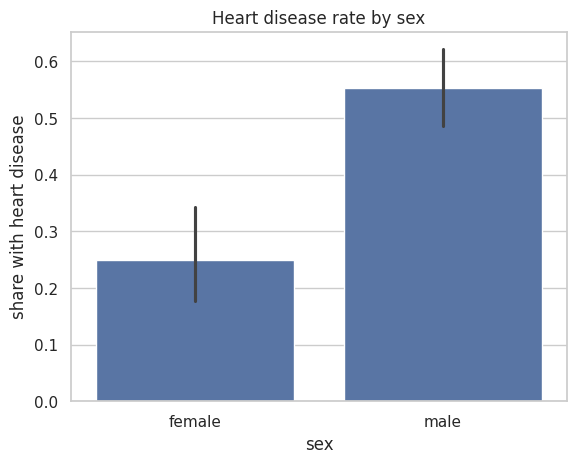

In [16]:
sns.barplot(x="sex", y="target", data=data)
plt.xticks([0, 1], ["female", "male"])
plt.ylabel("share with heart disease")
plt.title("Heart disease rate by sex")
plt.show()

In [17]:
data.groupby('target').mean(numeric_only=True).round(2)

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
target,,,,,,,,,,,,,
0,52.59,0.56,1.37,129.25,242.64,0.14,0.59,158.38,0.14,0.59,1.59,0.27,2.13
1,56.60,0.83,0.48,134.40,251.09,0.16,0.45,139.10,0.55,1.59,1.17,1.15,2.56


### Heart disease frequency for each age

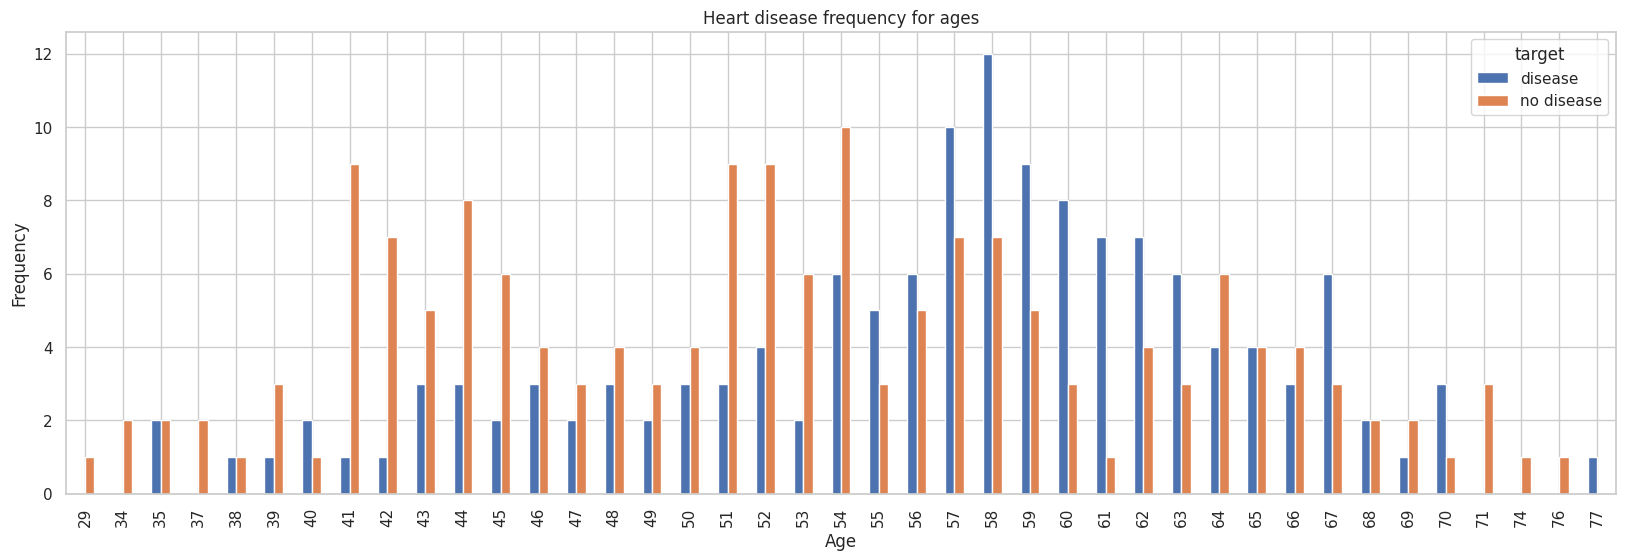

In [18]:
pd.crosstab(eda["age"], eda["target"]).plot(kind="bar", figsize=(20, 6))
plt.title("Heart disease frequency for ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.savefig("heartDiseaseAndAges.png")
plt.show()

### Heart disease frequency for males and females

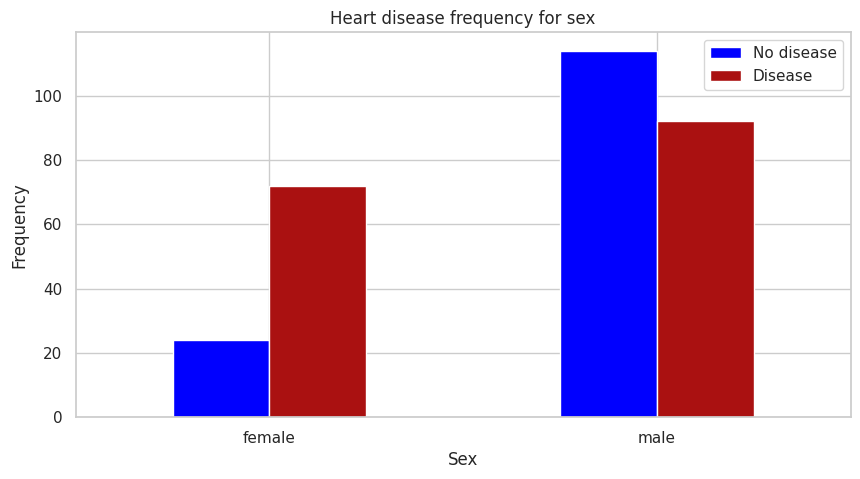

In [19]:
pd.crosstab(eda["sex"], eda["target"]).plot(kind="bar", figsize=(10, 5), color=["blue", "#AA1111"])
plt.title("Heart disease frequency for sex")
plt.xlabel("Sex")
plt.xticks(rotation=0)
plt.legend(["No disease", "Disease"])
plt.ylabel("Frequency")
plt.show()

###  Thalassemia vs cholesterol

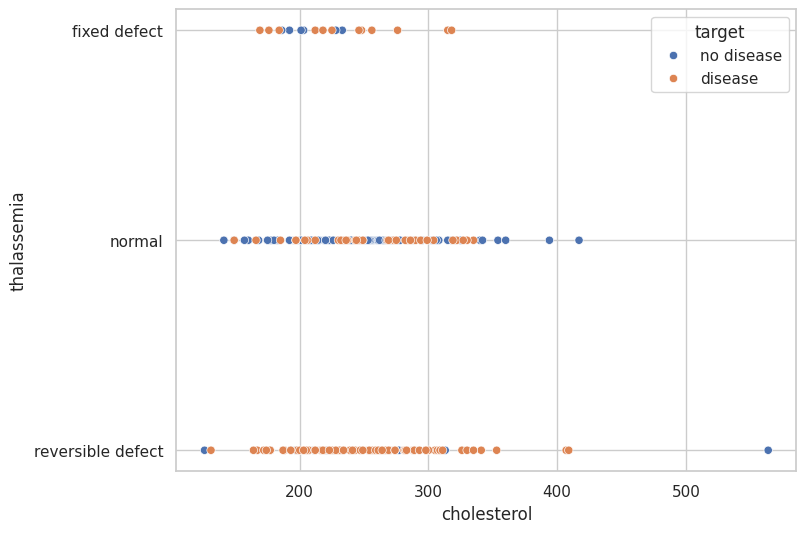

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="cholesterol", y="thalassemia", data=eda.dropna(subset=["thalassemia"]), hue="target")
plt.show()

### Thalassemia vs resting blood pressure

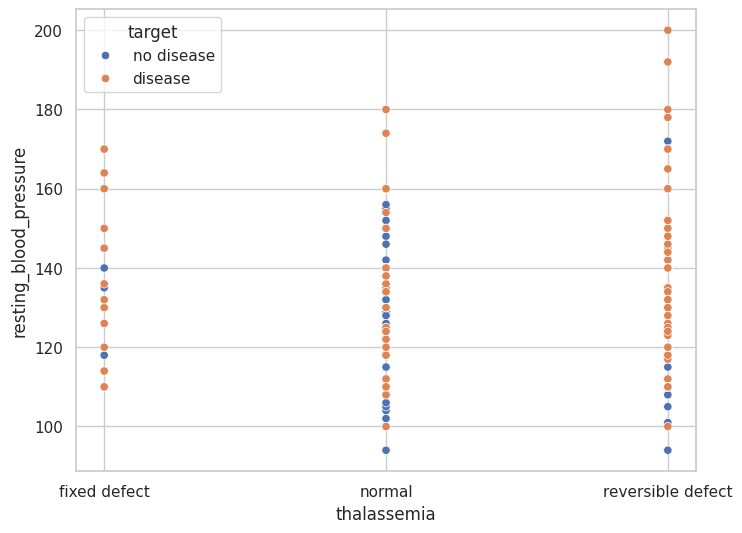

In [21]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="thalassemia", y="resting_blood_pressure", data=eda.dropna(subset=["thalassemia"]), hue="target")
plt.show()

### Age vs maximum heart rate



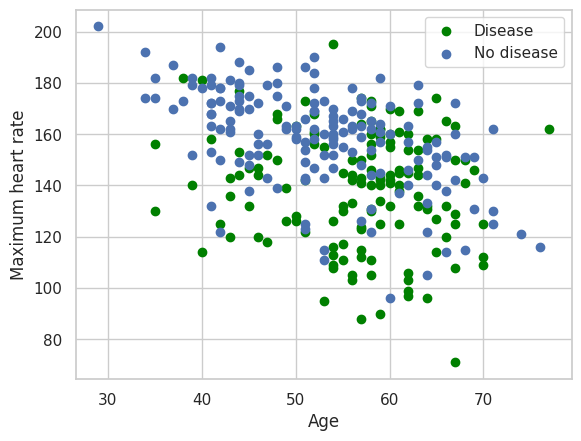

In [22]:
sick    = data[data["target"] == 1]
healthy = data[data["target"] == 0]
plt.scatter(sick["age"], sick["max_heart_rate_achieved"], c="green", label="Disease")
plt.scatter(healthy["age"], healthy["max_heart_rate_achieved"], label="No disease")
plt.legend()
plt.xlabel("Age")
plt.ylabel("Maximum heart rate")
plt.show()

###  Fasting blood sugar

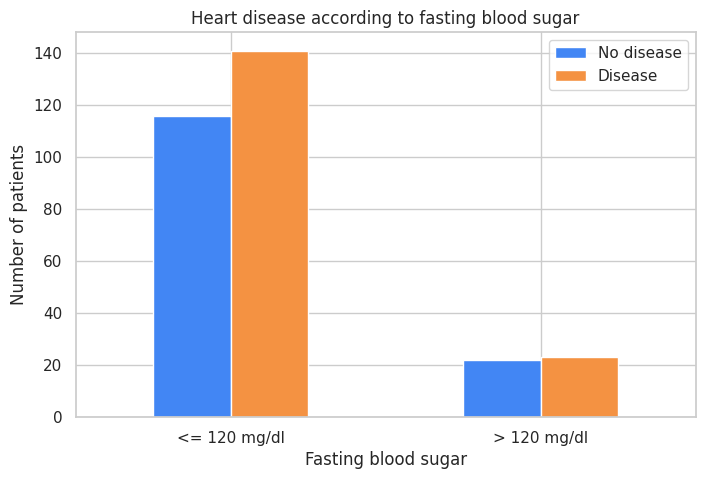

In [23]:
pd.crosstab(eda["fasting_blood_sugar"], eda["target"]).plot(kind="bar", figsize=(8, 5), color=["#4286f4", "#f49242"])
plt.title("Heart disease according to fasting blood sugar")
plt.xlabel("Fasting blood sugar")
plt.xticks(rotation=0)
plt.legend(["No disease", "Disease"])
plt.ylabel("Number of patients")
plt.show()

## Missing value analysis

In [24]:
data.isnull().sum()

,0
age,0
sex,0
chest_pain_type,0
resting_blood_pressure,0
cholesterol,0
fasting_blood_sugar,0
rest_ecg,0
max_heart_rate_achieved,0
exercise_induced_angina,0
st_depression,0


## Feature relationships (correlation)

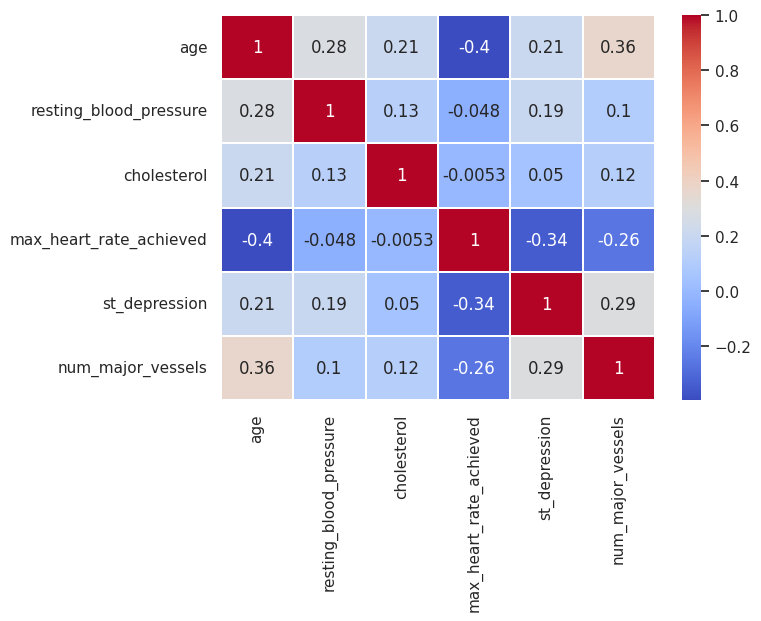

In [25]:
names = ["age", "resting_blood_pressure", "cholesterol", "max_heart_rate_achieved",
         "st_depression", "num_major_vessels"]
df_corr = data.loc[:, names]
corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.1, ax=ax)
plt.show()

In [26]:
df_corr.head()

,age,resting_blood_pressure,cholesterol,max_heart_rate_achieved,st_depression,num_major_vessels
0,63,145,233,150,2.3,0.0
1,37,130,250,187,3.5,0.0
2,41,130,204,172,1.4,0.0
3,56,120,236,178,0.8,0.0
4,57,120,354,163,0.6,0.0


## Train / test split and preprocessing

* **Features (`X`)** = everything except `target`; **label (`y`)** = `target`.
* 80% of patients train the model, 20% are kept hidden to test it. `stratify=y` keeps the same disease share in both parts.
* **Preprocessing** (done automatically inside a `Pipeline`):
  * number columns: fill gaps with the median, then scale to a similar range (important for KNN and Logistic Regression);
  * category columns (codes such as chest-pain type): fill gaps with the most frequent value, then one-hot encode, so the model does not think code 3 is "bigger" than code 1.

In [27]:
X = data.drop("target", axis=1)
y = data["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (241, 13) | X_test: (61, 13)
y_train: (241,) | y_test: (61,)


In [28]:
numeric_cols = ["age", "resting_blood_pressure", "cholesterol", "max_heart_rate_achieved",
                "st_depression", "num_major_vessels"]
category_cols = ["sex", "chest_pain_type", "fasting_blood_sugar", "rest_ecg",
                 "exercise_induced_angina", "st_slope", "thalassemia"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_cols),
        ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), category_cols),
    ])

def make_model(classifier):
    return Pipeline([("prep", make_preprocessor()), ("model", classifier)])

## A helper to test every model the same way

For each model we report:
* **Accuracy** on the hidden test set;
* **False Negative Rate (FNR)**: the percentage of sick patients the model wrongly calls healthy. In medicine this is the most dangerous mistake;
* **Cross-validation accuracy**: the data is split 5 different ways and the accuracy is averaged. With only ~60 test patients, one lucky split can mislead, so this is a more trustworthy number.

In [29]:
results = []
fitted_models = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model(name, classifier):
    pipe = make_model(classifier)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    accuracy = accuracy_score(y_test, y_pred) * 100
    fnr = fn * 100 / (fn + tp)
    cv_scores = cross_val_score(make_model(classifier), X, y, cv=cv, scoring="accuracy")
    auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])

    results.append({"Model": name, "Test accuracy %": round(accuracy, 2), "FNR %": round(fnr, 2),
                    "CV accuracy %": round(cv_scores.mean() * 100, 2),
                    "CV std %": round(cv_scores.std() * 100, 2), "ROC AUC": round(auc, 3)})
    fitted_models[name] = pipe

    print(f"{name}: test accuracy = {accuracy:.2f}%, FNR = {fnr:.2f}%, "
          f"5-fold CV accuracy = {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f})")
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["no disease", "disease"], cmap="Blues")
    plt.title(f"Confusion matrix: {name}")
    plt.show()
    return pipe, y_pred

##  Model fitting

###  Naive Bayes

Naive Bayes: test accuracy = 88.52%, FNR = 21.43%, 5-fold CV accuracy = 82.44% (+/- 4.43)


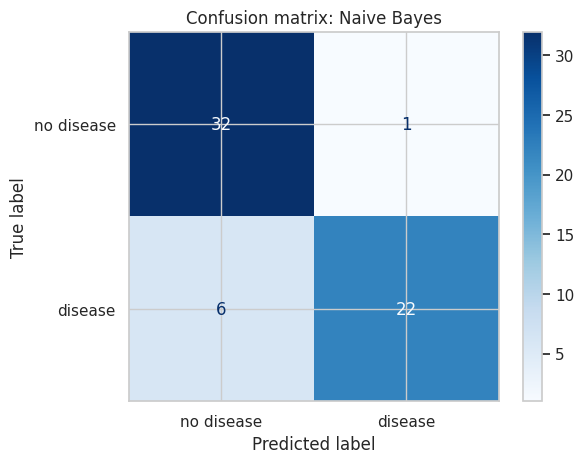

In [30]:
nb_pipe, y_pred_nb = evaluate_model('Naive Bayes', GaussianNB())

###  Decision Tree



Decision Tree: test accuracy = 88.52%, FNR = 17.86%, 5-fold CV accuracy = 80.50% (+/- 5.26)


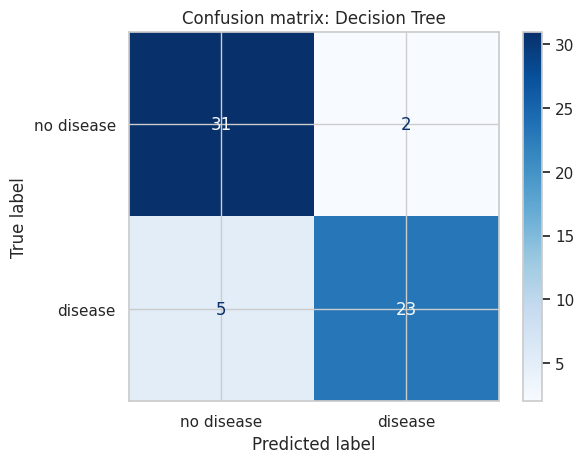

In [31]:
dt_pipe, y_pred_dt = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=RANDOM_STATE))

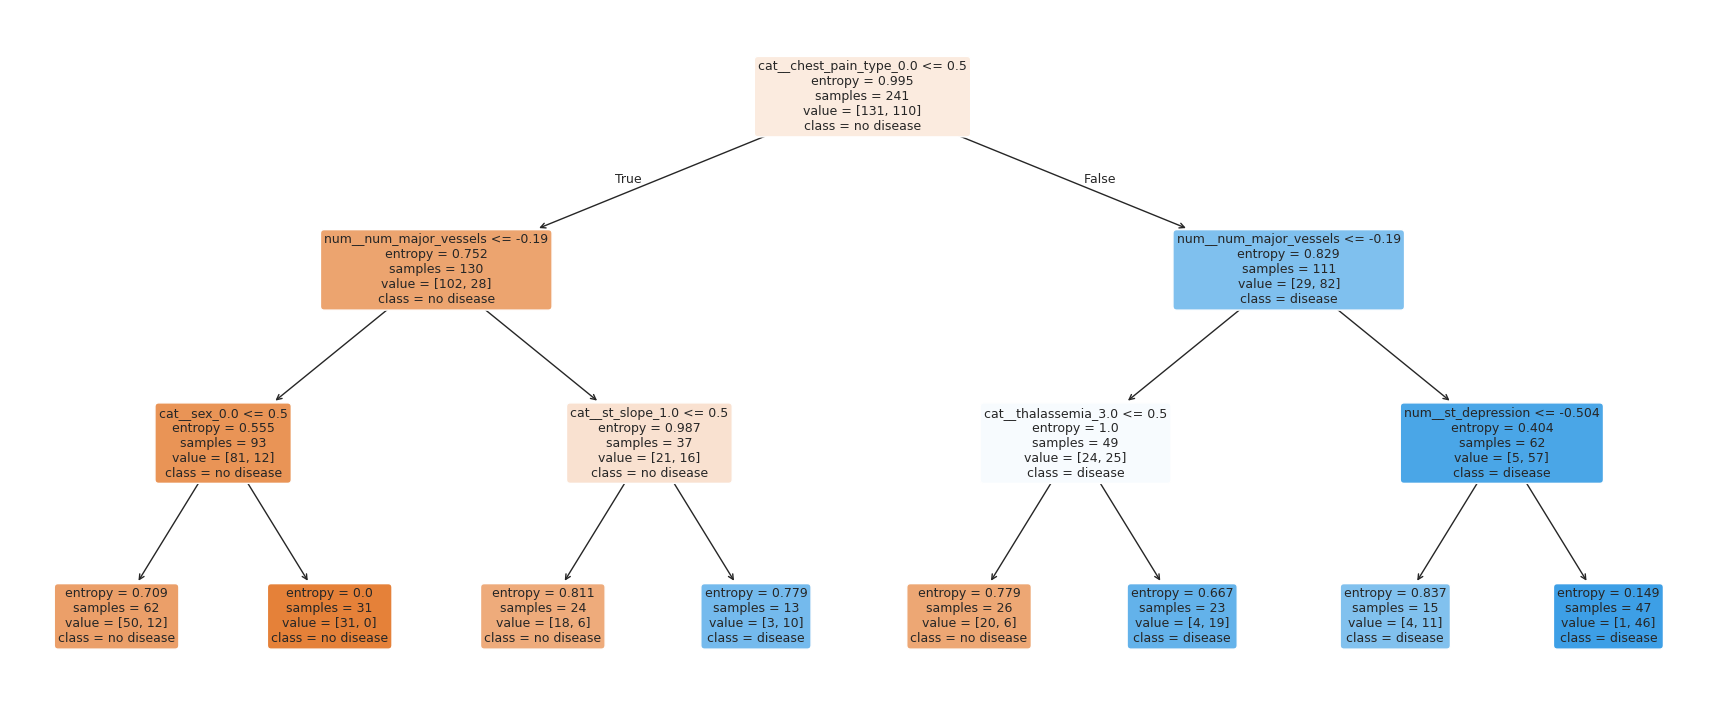

In [32]:
feature_names = dt_pipe.named_steps["prep"].get_feature_names_out()
plt.figure(figsize=(22, 9))
plot_tree(dt_pipe.named_steps["model"], feature_names=feature_names,
          class_names=["no disease", "disease"], filled=True, rounded=True, fontsize=9)
plt.show()

###  K-Nearest Neighbours (KNN)

KNN (k=7): test accuracy = 88.52%, FNR = 21.43%, 5-fold CV accuracy = 82.79% (+/- 4.23)


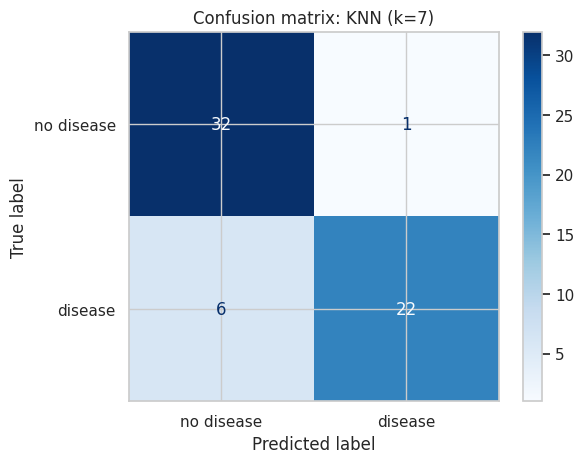

In [33]:
knn7_pipe, y_pred_knn7 = evaluate_model('KNN (k=7)', KNeighborsClassifier(n_neighbors=7))

KNN (k=4): test accuracy = 86.89%, FNR = 25.00%, 5-fold CV accuracy = 80.48% (+/- 2.75)


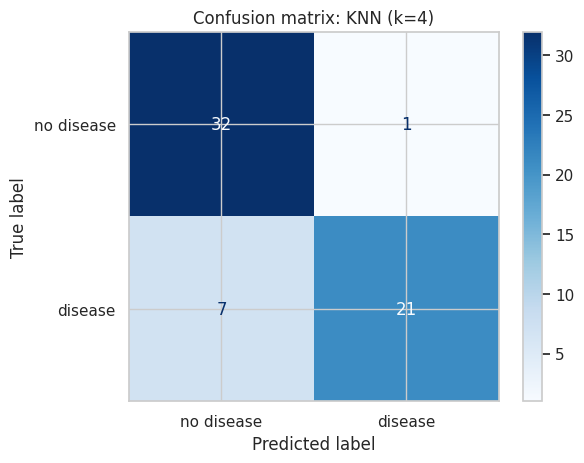

In [34]:
knn4_pipe, y_pred_knn4 = evaluate_model('KNN (k=4)', KNeighborsClassifier(n_neighbors=4))

Best k from cross-validation on training data: 17


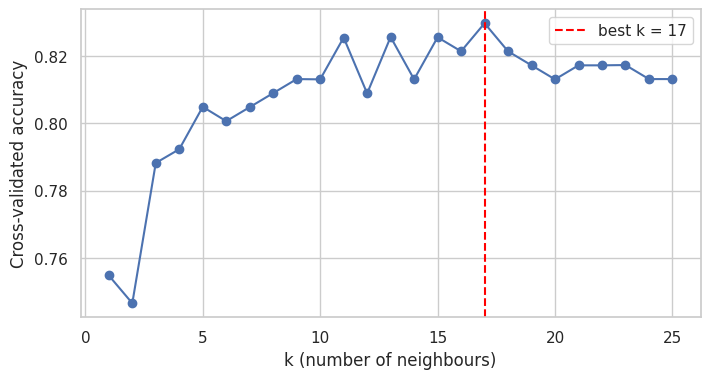

In [35]:
k_values = list(range(1, 26))
k_scores = []
for k in k_values:
    scores_k = cross_val_score(make_model(KNeighborsClassifier(n_neighbors=k)),
                               X_train, y_train, cv=cv, scoring="accuracy")
    k_scores.append(scores_k.mean())

best_k = k_values[int(np.argmax(k_scores))]
print("Best k from cross-validation on training data:", best_k)

plt.figure(figsize=(8, 4))
plt.plot(k_values, k_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated accuracy")
plt.legend()
plt.show()

KNN (best k=17): test accuracy = 88.52%, FNR = 21.43%, 5-fold CV accuracy = 82.44% (+/- 3.60)


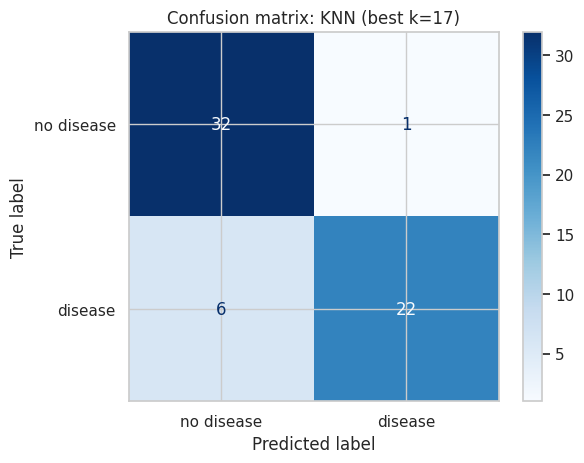

In [36]:
knn_best_pipe, y_pred_knn_best = evaluate_model(f'KNN (best k={best_k})', KNeighborsClassifier(n_neighbors=best_k))

###  Logistic Regression

Logistic Regression: test accuracy = 88.52%, FNR = 17.86%, 5-fold CV accuracy = 85.77% (+/- 3.23)


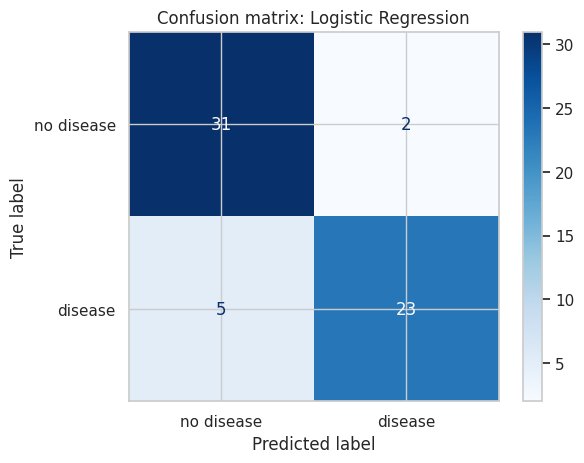

In [37]:
lr_pipe, y_pred_lr = evaluate_model('Logistic Regression', LogisticRegression(max_iter=1000))

In [38]:
print(classification_report(y_test, y_pred_lr, target_names=['no disease', 'disease']))

              precision    recall  f1-score   support

  no disease       0.86      0.94      0.90        33
     disease       0.92      0.82      0.87        28

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.88        61



##  Final score comparison

In [39]:
results_df = pd.DataFrame(results).sort_values("CV accuracy %", ascending=False).reset_index(drop=True)
results_df

,Model,Test accuracy %,FNR %,CV accuracy %,CV std %,ROC AUC
0,Logistic Regression,88.52,17.86,85.77,3.23,0.953
1,KNN (k=7),88.52,21.43,82.79,4.23,0.938
2,KNN (best k=17),88.52,21.43,82.44,3.60,0.943
3,Naive Bayes,88.52,21.43,82.44,4.43,0.951
4,Decision Tree,88.52,17.86,80.50,5.26,0.909
5,KNN (k=4),86.89,25.00,80.48,2.75,0.920


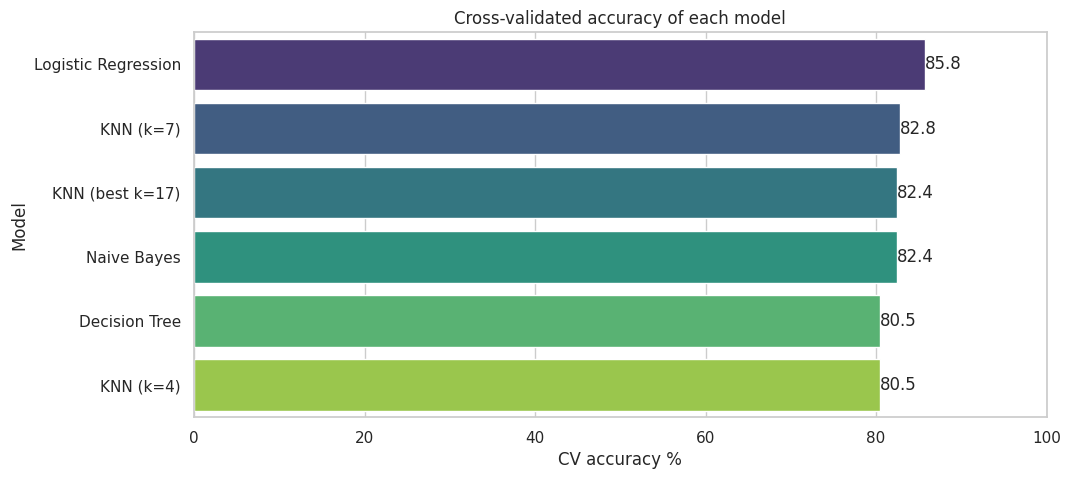

In [40]:
plt.figure(figsize=(11, 5))
ax = sns.barplot(x="CV accuracy %", y="Model", data=results_df, hue="Model", palette="viridis", legend=False)
ax.set_xlim(0, 100)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")
plt.title("Cross-validated accuracy of each model")
plt.show()

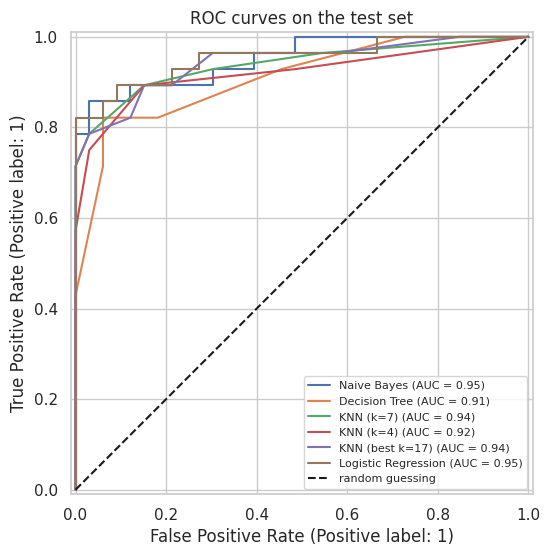

In [41]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="random guessing")
ax.legend(fontsize=8)
plt.title("ROC curves on the test set")
plt.show()

In [42]:
best = results_df.iloc[0]
print(f"Best model by cross-validation: {best['Model']} "
      f"({best['CV accuracy %']:.2f}% accuracy, ROC AUC on test set = {best['ROC AUC']})")

Best model by cross-validation: Logistic Regression (85.77% accuracy, ROC AUC on test set = 0.953)


## Predict for a new patient

The trained pipeline accepts raw numbers (it scales and encodes them by itself)

In [43]:
new_patient = pd.DataFrame([{
    "age": 58, "sex": 1, "chest_pain_type": 0, "resting_blood_pressure": 140,
    "cholesterol": 240, "fasting_blood_sugar": 0, "rest_ecg": 1,
    "max_heart_rate_achieved": 120, "exercise_induced_angina": 1, "st_depression": 2.0,
    "st_slope": 1, "num_major_vessels": 1, "thalassemia": 3}])

probability = lr_pipe.predict_proba(new_patient)[0, 1]
print(f"Logistic Regression: probability of heart disease = {probability * 100:.1f}%")
print("Prediction:", "disease" if probability >= 0.5 else "no disease")

Logistic Regression: probability of heart disease = 98.3%
Prediction: disease
